# 10 - Separable equations

**MATH 331 - Differential Equations.** Lecture plan: Session 4 (Unit 2: separable equations, implicit solutions, interval of validity; Torricelli's law).

**References**
* J. Lebl, *Notes on Diffy Qs*, **Section 1.3**: Examples 1.3.1-1.3.4, Subsection 1.3.1 and
  Figure 1.3.1 (implicit solutions), Exercises 1.3.3, 1.3.14, 1.3.16, 1.3.18.
* W.A. Adkins and M.G. Davidson, *Ordinary Differential Equations* (Springer, 2012), Section 1.1,
  Exercise 3 (the form of Torricelli's law: the rate is proportional to the square root of the
  height; the constant $\sqrt{2g}$ and the hole at the bottom are derived in Section 6).
* Exercise numbers are those of the exercise lists at the end of each chapter of the
  LibreTexts edition, unless "in the text" is said.
* Prerequisites: videos R02 (substitution), R04 (partial fractions), R01 (chain rule);
  notebook 09.

**What you will learn**
1. The first **method** of the course: separate, integrate, solve for $y$, check.
2. Three things a formula does not say by itself: a solution can be **lost** when you divide;
   a solution may be only **implicit**; a solution lives on an **interval**.
3. The method at work: how long does a tank take to drain?

## 1. Theory in brief

A first-order equation is **separable** when the right-hand side is a product of a function of
$x$ and a function of $y$:

$$ \frac{dy}{dx} = f(x)\,g(y) . $$

**The method.**

0. *Constant solutions first.* If $g(y_0) = 0$, then $y = y_0$ is a solution. Write these down
   **before** dividing: step 1 loses them.
1. *Separate*: $\dfrac{dy}{g(y)} = f(x)\,dx$, all the $y$ on the left, all the $x$ on the right.
2. *Integrate* both sides: $\displaystyle\int \frac{dy}{g(y)} = \int f(x)\,dx + C$ (one constant
   is enough).
3. *Solve for $y$*, if you can. If you cannot, the relation between $x$ and $y$ is an
   **implicit solution**.
4. *Check*, by differentiating (notebook 09), and say **on which interval** the solution lives.

**Why may we integrate one side in $y$ and the other in $x$?** Since $y = y(x)$, the equation is
$\dfrac{1}{g(y)}\dfrac{dy}{dx} = f(x)$. Integrating both sides in $x$, the left side is
$\displaystyle\int \frac{1}{g(y(x))}\,y'(x)\,dx$, which the substitution $y = y(x)$ turns into
$\displaystyle\int\frac{dy}{g(y)}$ (video R02).

In [1]:
# --- Setup ---------------------------------------------------------------------
# odelib.py lives next to the notebooks: it contains the tested helper functions
# (here: slope_field, solution_curve, torricelli_height, torricelli_drain_time, check).
import sys
import pathlib
sys.path.insert(0, str(pathlib.Path.cwd()))

import numpy as np
import sympy as sp
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from IPython.display import Math, display                 # noqa: F401  (not used in every notebook)
from ipywidgets import FloatSlider, IntSlider, interact    # noqa: F401

import odelib as ol

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3,
                     "font.size": 11, "legend.fontsize": 9})
print("numpy", np.__version__, "| sympy", sp.__version__)

numpy 2.5.4 | sympy 1.14.0


## 2. The method, step by step

*Lebl, Example 1.3.1.* Solve $y' = xy$ (the equation of the slope fields of notebook 09).

By hand:

0. $y = 0$ is a solution. From now on $y \ne 0$.
1. $\dfrac{dy}{y} = x\,dx$.
2. $\ln|y| = \dfrac{x^2}{2} + C$.
3. $|y| = e^{C}e^{x^2/2}$, that is $y = D\,e^{x^2/2}$ with $D = \pm e^{C}$ any number different
   from 0. With $D = 0$ the formula also gives the solution $y = 0$ of step 0: **every** $D$ is
   allowed.
4. Check: $y' = D\,x\,e^{x^2/2} = x\,y$.

The same steps with SymPy. The computer does the two integrals; you decide what to integrate.

In [2]:
x, y, t, C, D = sp.symbols("x y t C D")


def residual(left, right=0):
    # left side minus right side of an equation, simplified: 0 for a solution (notebook 09)
    return sp.simplify(left - right)


left = sp.integrate(1 / y, y)                 # step 2, left side
right = sp.integrate(x, x)                    # step 2, right side
print("integrals:", left, "=", right, "+ C")

solved = sp.solve(sp.Eq(left, right + C), y)  # step 3
print("solved for y:", solved)

general = D * sp.exp(x ** 2 / 2)              # the same family, with D = exp(C)
print("check (step 4), residual:", residual(sp.diff(general, x), x * general))
assert residual(sp.diff(general, x), x * general) == 0

integrals: log(y) = x**2/2 + C


solved for y: [exp(C + x**2/2)]
check (step 4), residual: 0


SymPy writes `log(y)` without the absolute value, and finds $y = e^{C + x^2/2}$: only the
solutions with $D > 0$. The negative ones, and $y = 0$, come from the absolute value and from
step 0: **your** part of the work.

The initial condition chooses $D$: $y(0) = D$. In notebook 09 the curves were computed
numerically; now they have a formula.

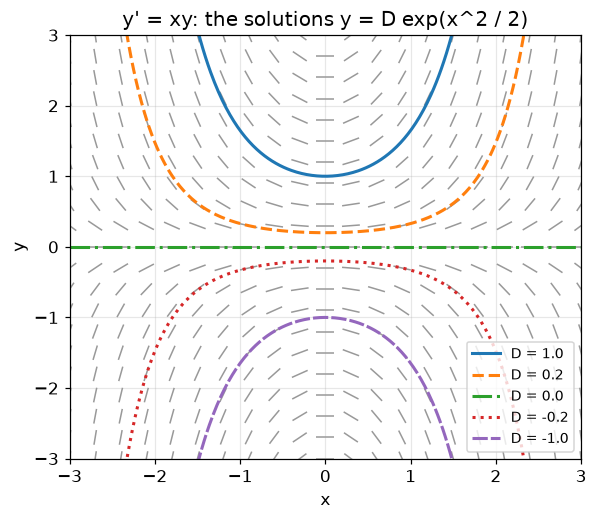

y(2) = 1.4778 (formula), 1.4778 (numerical)


In [3]:
def f_xy(x, y):
    return x * y


X_RANGE = (-3.0, 3.0)
Y_RANGE = (-3.0, 3.0)
FIGURE_SIZE = (6.0, 5.0)
N_POINTS = 400
D_VALUES = (1.0, 0.2, 0.0, -0.2, -1.0)
LINE_STYLES = ("-", "--", "-.", ":", (0, (5, 1)))
X_CHECK = 2.0

x_values = np.linspace(*X_RANGE, N_POINTS)

fig, ax = plt.subplots(figsize=FIGURE_SIZE)
ol.slope_field(ax, f_xy, X_RANGE, Y_RANGE)
for d, style in zip(D_VALUES, LINE_STYLES):
    ax.plot(x_values, d * np.exp(x_values ** 2 / 2), linestyle=style, linewidth=2, label=f"D = {d}")
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_title("y' = xy: the solutions y = D exp(x^2 / 2)")
ax.legend(loc="lower right")
plt.show()

# formula against the numerical curve of notebook 09, for y(0) = 0.2
d = D_VALUES[1]
x_curve, y_curve = ol.solution_curve(f_xy, (0.0, d), X_RANGE, Y_RANGE)
print(f"y({X_CHECK:.0f}) = {d * np.exp(X_CHECK ** 2 / 2):.4f} (formula), "
      f"{np.interp(X_CHECK, x_curve, y_curve):.4f} (numerical)")
assert np.isclose(np.interp(X_CHECK, x_curve, y_curve), d * np.exp(X_CHECK ** 2 / 2))

*The plot shows* five solutions $y = D\,e^{x^2/2}$ on the slope field of $y' = xy$: valleys above
the $x$ axis for $D > 0$, their mirror images below for $D < 0$, and the axis itself for $D = 0$.
All of them follow the grey segments.

## 3. A solution lost on the way

*Lebl, Example 1.3.4.* Find **all** the solutions of $\;y' = -\dfrac{x\,y^2}{3}$.

0. $y = 0$ is a solution.
1. For $y \ne 0$: $\;-\dfrac{3}{y^2}\,dy = x\,dx$.
2. $\dfrac{3}{y} = \dfrac{x^2}{2} + C$.
3. $y = \dfrac{6}{x^2 + 2C}$.

Is $y = 0$ in this family, for some value of $C$? No: a fraction with numerator 6 is never zero.
It is a **singular solution**: a solution that the general formula does not contain. Had we
skipped step 0, we would have lost it.

residual of the family: 0
residual of y = 0     : 0


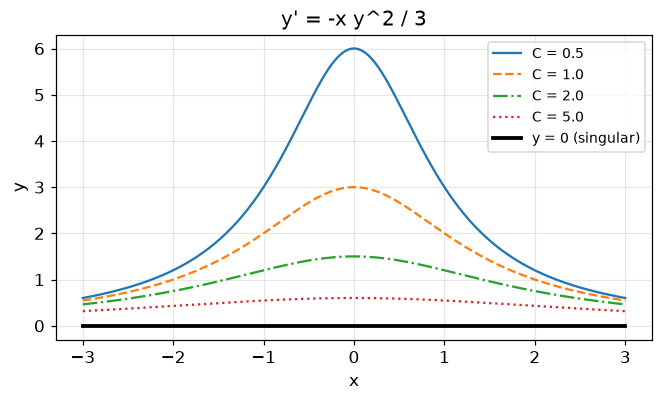

In [4]:
family = 6 / (x ** 2 + 2 * C)
print("residual of the family:", residual(sp.diff(family, x), -x * family ** 2 / 3))
print("residual of y = 0     :", residual(sp.diff(sp.Integer(0), x), -x * sp.Integer(0) ** 2 / 3))
assert residual(sp.diff(family, x), -x * family ** 2 / 3) == 0

C_VALUES = (0.5, 1.0, 2.0, 5.0)
WIDE_FIGURE = (7.0, 3.6)

fig, ax = plt.subplots(figsize=WIDE_FIGURE)
for c, style in zip(C_VALUES, LINE_STYLES):
    ax.plot(x_values, 6 / (x_values ** 2 + 2 * c), linestyle=style, label=f"C = {c}")
ax.plot(x_values, np.zeros_like(x_values), "-", color="black", linewidth=2.5, label="y = 0 (singular)")
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_title("y' = -x y^2 / 3")
ax.legend(loc="upper right")
plt.show()

*The plot shows* four bell-shaped curves $y = 6/(x^2 + 2C)$, lower and flatter as $C$ grows, and
the thick black line $y = 0$. The bells get closer and closer to the line as $C \to \infty$, but none
of them is the line.

## 4. Implicit solutions

*Lebl, Subsection 1.3.1.* $\;y' = \dfrac{x\,y}{y^2 + 1}$.

1. $\dfrac{y^2 + 1}{y}\,dy = \Big(y + \dfrac1y\Big)dy = x\,dx$.
2. $\dfrac{y^2}{2} + \ln|y| = \dfrac{x^2}{2} + C$, or, with a new constant,

$$ y^2 + 2\ln|y| = x^2 + C . $$

3. Solve for $y$... not with the functions you know. The relation above **is** the answer: an *implicit solution*.
   (And $y = 0$ is a singular solution.)

It can still be **checked**: differentiate both sides in $x$, remembering that $y = y(x)$:
$\;2y\,y' + \dfrac{2}{y}\,y' = 2x$, that is $y' = \dfrac{xy}{y^2+1}$. SymPy does this with `idiff`
(implicit differentiation).

It can still be **drawn**: the computer finds the points $(x, y)$ where
$y^2 + 2\ln|y| - x^2$ has a given value $C$ (a *level curve*).

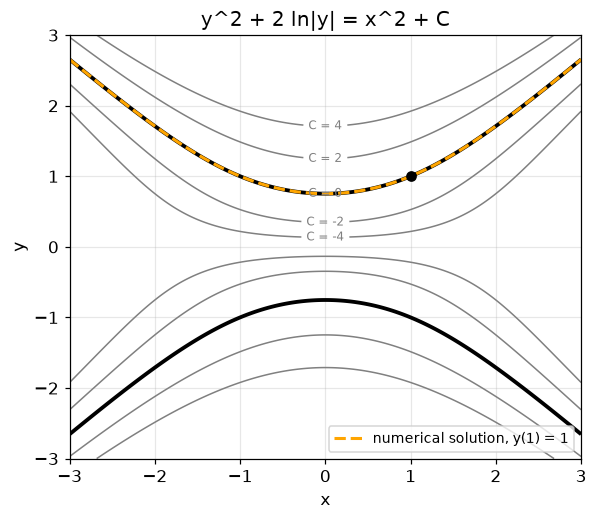

y(2) = 1.7106 (implicit relation), 1.7106 (numerical)


In [5]:
from scipy.optimize import brentq             # finds a root of a function between two points


def level(x, y):
    # the quantity that stays constant along a solution of y' = x y / (y^2 + 1)
    return y ** 2 + 2 * np.log(np.abs(y)) - x ** 2


def f_implicit(x, y):
    return x * y / (y ** 2 + 1)


# check by implicit differentiation
slope = sp.idiff(y ** 2 + 2 * sp.log(y) - x ** 2, y, x)
assert residual(slope, x * y / (y ** 2 + 1)) == 0

GRID = 400                                    # even: the grid does not contain y = 0
LEVELS = (-4.0, -2.0, 0.0, 2.0, 4.0)
START = (1.0, 1.0)                            # the initial condition y(1) = 1 (it gives C = 0)
X_TARGET = 2.0
BRACKET = (1.0, 3.0)                          # y(2) is between these two values
LABEL_BRACKET = (0.01, 3.0)                   # where each level curve crosses the y axis

grid_x, grid_y = np.meshgrid(np.linspace(*X_RANGE, GRID), np.linspace(*Y_RANGE, GRID))

fig, ax = plt.subplots(figsize=FIGURE_SIZE)
contours = ax.contour(grid_x, grid_y, level(grid_x, grid_y), levels=LEVELS,
                      colors="gray", linestyles="-", linewidths=1)
label_points = [(0.0, brentq(lambda value, c=c: level(0.0, value) - c, *LABEL_BRACKET)) for c in LEVELS]
ax.clabel(contours, fmt="C = %g", fontsize=8, manual=label_points)      # labels on the y axis, upper family
ax.contour(grid_x, grid_y, level(grid_x, grid_y), levels=[level(*START)], colors="black", linewidths=2.5)
x_curve, y_curve = ol.solution_curve(f_implicit, START, X_RANGE, Y_RANGE)
ax.plot(x_curve, y_curve, "--", color="orange", linewidth=2, label="numerical solution, y(1) = 1")
ax.plot(*START, "o", color="black")
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_title("y^2 + 2 ln|y| = x^2 + C")
ax.legend(loc="lower right")
plt.show()

# a value from the implicit solution: solve  y^2 + 2 ln y = 2^2  for y
y_implicit = brentq(lambda value: level(X_TARGET, value), *BRACKET)
y_numerical = np.interp(X_TARGET, x_curve, y_curve)
print(f"y({X_TARGET:.0f}) = {y_implicit:.4f} (implicit relation), {y_numerical:.4f} (numerical)")
assert np.isclose(y_implicit, y_numerical)

*The plot shows* the level curves of $y^2 + 2\ln|y| - x^2$ for five values of $C$ (thin grey
lines, labelled), in two mirror-image families above and below the $x$ axis. The thick black
curve is the level $C = 0$ (Lebl, Figure 1.3.1): it has two branches. The dashed orange curve,
computed numerically from $y(1) = 1$, lies exactly on the upper branch.

Two lessons. The relation $y^2 + 2\ln|y| = x^2$ describes **two** solutions (upper and lower
branch); the initial condition says which one. And to get a number, such as $y(2)$, an equation
must be solved numerically: here `brentq` looks for the root between 1 and 3.

## 5. Where does the solution live?

*Lebl, Example 1.3.2.* $\;x^2 y' = 1 - x^2 + y^2 - x^2y^2$, $\;y(1) = 0$.

The right-hand side factors: $(1 - x^2)(1 + y^2)$. Then

$$ \frac{dy}{1 + y^2} = \Big(\frac{1}{x^2} - 1\Big)dx
\;\Longrightarrow\; \arctan y = -\frac1x - x + C
\;\Longrightarrow\; y = \tan\Big(-\frac1x - x + C\Big), $$

and $y(1) = 0$ gives $C = 2$: $\;y = \tan\!\big(2 - x - \tfrac1x\big)$.

**But for which $x$?** The formula can be evaluated for almost every $x$. The *solution* of the
initial value problem is only the piece of the graph **through the initial point** $(1, 0)$, up
to the first place where it breaks. The tangent breaks when its argument reaches
$\pm\tfrac{\pi}{2}$. The argument $2 - x - \tfrac1x$ is 0 at $x = 1$ and smaller for every other $x > 0$,
so it reaches $-\tfrac{\pi}{2}$ on both sides: where $x + \tfrac1x = 2 + \tfrac{\pi}{2}$, that is
$x^2 - \big(2 + \tfrac{\pi}{2}\big)x + 1 = 0$.

the solution lives on  0.306 < x < 3.264


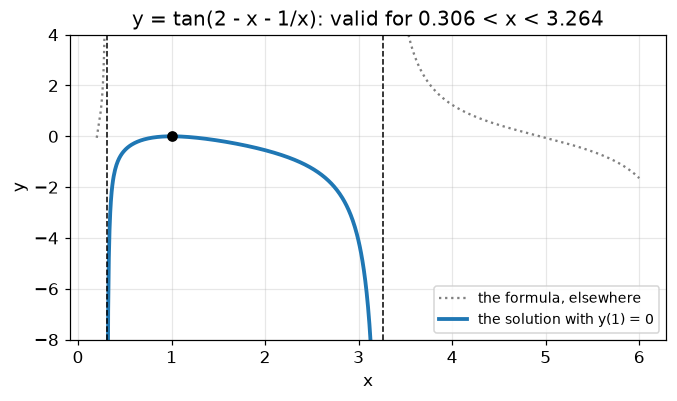

In [6]:
solution = sp.tan(2 - x - 1 / x)
assert residual(x ** 2 * sp.diff(solution, x), (1 - x ** 2) * (1 + solution ** 2)) == 0
assert solution.subs(x, 1) == 0

ends = np.sort(np.roots([1.0, -(2 + np.pi / 2), 1.0]))        # x^2 - (2 + pi/2) x + 1 = 0
print(f"the solution lives on  {ends[0]:.3f} < x < {ends[1]:.3f}")

PLOT_RANGE = (0.2, 6.0)
Y_LIMITS = (-8.0, 4.0)
MARGIN = 1e-3                                 # stay away from the asymptotes


def formula(x):
    return np.tan(2 - x - 1 / x)


x_all = np.linspace(*PLOT_RANGE, 4000)
y_all = formula(x_all)
y_all[np.abs(y_all) > 2 * max(np.abs(Y_LIMITS))] = np.nan     # do not join the branches
x_valid = np.linspace(ends[0] + MARGIN, ends[1] - MARGIN, N_POINTS)

fig, ax = plt.subplots(figsize=WIDE_FIGURE)
ax.plot(x_all, y_all, ":", color="gray", label="the formula, elsewhere")
ax.plot(x_valid, formula(x_valid), "-", linewidth=2.5, label="the solution with y(1) = 0")
for end in ends:
    ax.axvline(end, linestyle="--", color="black", linewidth=1)
ax.plot(1.0, 0.0, "o", color="black")
ax.set_ylim(*Y_LIMITS)
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_title(f"y = tan(2 - x - 1/x): valid for {ends[0]:.3f} < x < {ends[1]:.3f}")
ax.legend(loc="lower right")
plt.show()

assert np.allclose(ends, [0.306, 3.264], atol=1e-3)
assert np.isclose(ends[0] * ends[1], 1.0)                     # the two ends are reciprocal

*The plot shows* the graph of $\tan(2 - x - 1/x)$. The thick piece through the black dot $(1, 0)$
is the solution: it touches zero at $x = 1$ and falls to $-\infty$ at both dashed vertical lines,
$x \approx 0.306$ and $x \approx 3.264$. The dotted pieces outside are other branches of the same
formula; they are **not** part of the solution of this initial value problem.

The same happened in notebook 09 (Exercise 4): $y' = y^2$, $y(0) = A > 0$ gives
$y = \dfrac{1}{1/A - x}$, which lives only for $x < 1/A$.

**The habit:** an answer to an initial value problem is a formula **and** an interval containing
the initial point.

## 6. Torricelli's law: draining a tank

A cylindrical tank with cross-section $A$ has a small hole of area $a$ at the bottom. Water of
height $h$ leaves the hole with the speed of a body fallen from height $h$, $v = \sqrt{2gh}$
(Torricelli's law). In a short time the volume lost, $a\,v\,dt$, equals $-A\,dh$:

$$ \frac{dh}{dt} = -\frac{a}{A}\sqrt{2g\,h}, \qquad h(0) = h_0 . $$

It is separable (and $h = 0$ is a constant solution: an empty tank stays empty). By hand, with
$c = \dfrac{a}{A}\sqrt{2g}$:

$$ \frac{dh}{\sqrt h} = -c\,dt \;\Longrightarrow\; 2\sqrt h = 2\sqrt{h_0} - c\,t
\;\Longrightarrow\; h(t) = \Big(\sqrt{h_0} - \frac{a}{A}\sqrt{\frac g2}\;t\Big)^2 . $$

The tank is empty when the bracket vanishes:

$$ \boxed{\,T = \frac{A}{a}\sqrt{\frac{2h_0}{g}}\,} $$

The solution lives on $0 \le t \le T$; after $T$ the height stays 0.

**Data.** A tank of radius 0.5 m, filled to 1 m, with a hole of radius 1 cm.

In [7]:
G = ol.GRAVITY              # 9.81 m/s^2
TANK_RADIUS = 0.5           # m
HOLE_RADIUS = 0.01          # m
H0 = 1.0                    # m
SECONDS_PER_MINUTE = 60.0


def area_ratio(hole_radius, tank_radius=TANK_RADIUS):
    return (hole_radius / tank_radius) ** 2            # a / A: the factors pi cancel


T_drain = ol.torricelli_drain_time(H0, area_ratio(HOLE_RADIUS), G)
print(f"draining time: {T_drain:.1f} s = {T_drain / SECONDS_PER_MINUTE:.1f} minutes")

# check of the formula by hand: residual of h' = -(a/A) sqrt(2 g h), with sqrt(h) = the bracket
ratio, gravity, start = sp.symbols("ratio gravity start", positive=True)
bracket = sp.sqrt(start) - ratio * sp.sqrt(gravity / 2) * t
assert residual(sp.diff(bracket ** 2, t), -ratio * sp.sqrt(2 * gravity) * bracket) == 0
assert np.isclose(T_drain, 1128.8, atol=0.05)

draining time: 1128.8 s = 18.8 minutes


Now the numerical solution, with `solve_ivp`, beyond the draining time.

**A remark on rounding** (notebook 08, Section 6). Near the end $h$ is almost 0, and the tiny
errors of the computer can make it $-10^{-12}$: the square root of a negative number does not
exist, and the computation would fail. The remedy is one line: never take the root of a negative
height, `np.maximum(h, 0.0)`.

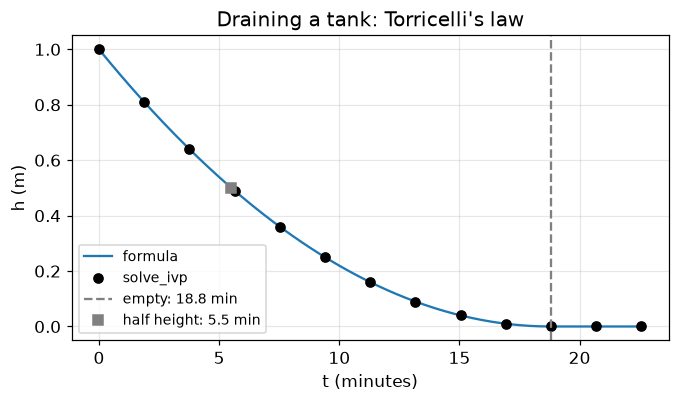

half of the height is lost in the first 29% of the time


In [8]:
def draining(t, h):
    return -area_ratio(HOLE_RADIUS) * np.sqrt(2 * G * np.maximum(h, 0.0))


BEYOND = 1.2                # plot up to 1.2 times the draining time
N_DOTS = 13
TOLERANCE = 1e-9

numerical = solve_ivp(draining, (0.0, BEYOND * T_drain), [H0], dense_output=True,
                      rtol=TOLERANCE, atol=TOLERANCE)

t_fine = np.linspace(0.0, BEYOND * T_drain, N_POINTS)
t_dots = np.linspace(0.0, BEYOND * T_drain, N_DOTS)
t_half = T_drain * (1 - 1 / np.sqrt(2))                # where h = h0 / 2

fig, ax = plt.subplots(figsize=WIDE_FIGURE)
ax.plot(t_fine / SECONDS_PER_MINUTE, ol.torricelli_height(t_fine, H0, area_ratio(HOLE_RADIUS), G),
        "-", label="formula")
ax.plot(t_dots / SECONDS_PER_MINUTE, numerical.sol(t_dots)[0], "o", color="black", label="solve_ivp")
ax.axvline(T_drain / SECONDS_PER_MINUTE, linestyle="--", color="gray",
           label=f"empty: {T_drain / SECONDS_PER_MINUTE:.1f} min")
ax.plot(t_half / SECONDS_PER_MINUTE, H0 / 2, "s", color="gray",
        label=f"half height: {t_half / SECONDS_PER_MINUTE:.1f} min")
ax.set_xlabel("t (minutes)")
ax.set_ylabel("h (m)")
ax.set_title("Draining a tank: Torricelli's law")
ax.legend()
plt.show()

assert np.allclose(numerical.sol(t_dots)[0], ol.torricelli_height(t_dots, H0, area_ratio(HOLE_RADIUS), G),
                   atol=1e-6)
print(f"half of the height is lost in the first {t_half / T_drain:.0%} of the time")

*The plot shows* the height of the water against time: it falls from 1 m, quickly at first and
then more and more slowly, and reaches 0 with a horizontal tangent after 18.8 minutes (dashed
line); from then on it stays 0. The dots (numerical solution) lie on the curve (formula). The
grey square marks half the height, reached after only 5.5 minutes.

**Sliders.** Answer *before* moving them (use the formula for $T$):

1. The hole is twice as wide (radius 2 cm). The draining time is divided by ...?
2. The water is twice as high (2 m). The draining time is multiplied by ...?

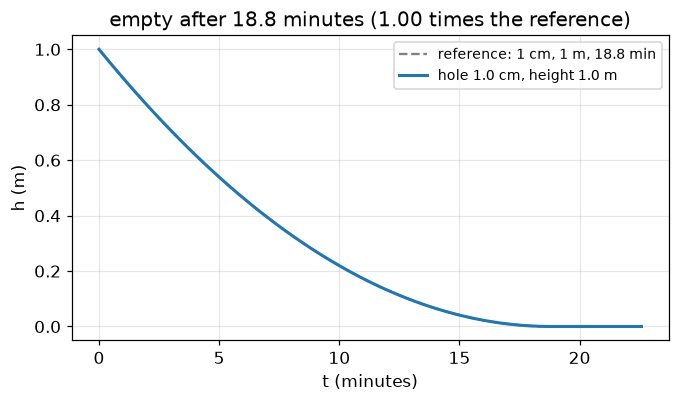

In [9]:
CM_PER_M = 100.0


def plot_tank(hole_cm=HOLE_RADIUS * CM_PER_M, h0=H0):
    ratio_now = area_ratio(hole_cm / CM_PER_M)
    T_now = ol.torricelli_drain_time(h0, ratio_now, G)
    t_end = BEYOND * max(T_now, T_drain)
    times = np.linspace(0.0, t_end, N_POINTS)
    fig, ax = plt.subplots(figsize=WIDE_FIGURE)
    ax.plot(times / SECONDS_PER_MINUTE, ol.torricelli_height(times, H0, area_ratio(HOLE_RADIUS), G),
            "--", color="gray", label=f"reference: 1 cm, 1 m, {T_drain / SECONDS_PER_MINUTE:.1f} min")
    ax.plot(times / SECONDS_PER_MINUTE, ol.torricelli_height(times, h0, ratio_now, G),
            "-", linewidth=2, label=f"hole {hole_cm:.1f} cm, height {h0:.1f} m")
    ax.set_xlabel("t (minutes)")
    ax.set_ylabel("h (m)")
    ax.set_title(f"empty after {T_now / SECONDS_PER_MINUTE:.1f} minutes "
                 f"({T_now / T_drain:.2f} times the reference)")
    ax.legend()
    plt.show()


plot_tank()                 # the picture without sliders: the reference tank

In [10]:
HOLE_RANGE = (0.5, 3.0, 0.1)            # minimum, maximum, step (cm)
HEIGHT_RANGE = (0.2, 2.0, 0.1)          # minimum, maximum, step (m)

interact(plot_tank,
         hole_cm=FloatSlider(value=HOLE_RADIUS * CM_PER_M, min=HOLE_RANGE[0], max=HOLE_RANGE[1],
                             step=HOLE_RANGE[2], description="hole (cm)", continuous_update=False),
         h0=FloatSlider(value=H0, min=HEIGHT_RANGE[0], max=HEIGHT_RANGE[1], step=HEIGHT_RANGE[2],
                        description="height (m)", continuous_update=False));

interactive(children=(FloatSlider(value=1.0, continuous_update=False, description='hole (cm)', max=3.0, min=0....

(Divided by 4: the area of the hole is 4 times larger. Multiplied by $\sqrt2 \approx 1.41$, not
by 2: higher water also leaves faster.)

## 7. Look back

After the time $T$ the tank is empty and stays empty: for $t \ge T$ the solution is the constant
solution $h = 0$ of step 0, glued to the parabola.

Now read the film backwards. You enter a room and see an **empty** tank. When did it become
empty: a minute ago, an hour ago? You cannot tell. All these histories end in the same state,
$h = 0$: through that state pass **many** solutions. It is the same phenomenon as
$y' = 2\sqrt{|y|}$ in notebook 09 (Section 7): uniqueness fails where the square root has a
vertical tangent, at $h = 0$. Session 5 (notebook 11) gives the theorem that says when this
cannot happen.

## 8. Exercises

Final answers are at the end; try first.

**Before you start:** run the whole notebook (the `>>` button at the top, then *Confirm Kernel Restart*; or the menu *Run > Run All Cells*), every time you open it: the exercises use what the
cells above define. In an answer cell change only the lines above the line that starts with `# ----`, then press Shift+Enter. If Python does not accept what you type, see "How to type
mathematics" in notebook 00, or click `+` at the top, type `ol.guide("typing")` in the new cell and press Shift+Enter.

### Exercise 1 - Predict (no computer)

A tank like the one of Section 6 takes 20 minutes to drain.

* After 10 minutes, is it half empty, less than half empty, or more than half empty?
* With a hole twice as wide, how long does it take?

Then check your answers with the plot and the sliders of Section 6.

### Exercise 2 - By hand, then check

**(a)** *Lebl, Exercise 1.3.14.* Solve $x' = 3x\,t^2 - 3t^2$, $x(0) = 2$ (factor the right-hand
side first). Type your solution in place of `None`, as an expression in `t`: for example
`sp.exp(t) + 1` (which is not the answer).

In [11]:
my_x = None
# ---- your answers go above this line; the lines below check them (nothing to change) ----

T_INTERVAL = (-1.0, 1.0)                # the two formulas are compared at a few points of this interval
ol.check_formula("Exercise 2a", my_x, sp.exp(t ** 3) + 1, t, T_INTERVAL);

Exercise 2a: no answer yet (replace None with your formula)


**(b)** *Lebl, Exercise 1.3.16.* Solve $x\,y' = y^2$, $y(1) = 1$. Type the solution (an expression
in `x`; the natural logarithm is `sp.log`) and the **right end** of its interval of validity
(a number; `np.e` is the number $e$).

In [12]:
my_y = None
my_right_end = None
# ---- your answers go above this line; the lines below check them (nothing to change) ----

X_INTERVAL = (0.5, 2.5)                 # inside the interval of validity
ROUNDING = 1e-3                         # an answer rounded to three decimals is accepted

ol.check_formula("Exercise 2b, solution", my_y, 1 / (1 - sp.log(x)), x, X_INTERVAL)
ol.check("Exercise 2b, right end", my_right_end, np.e, tol=ROUNDING);

Exercise 2b, solution: no answer yet (replace None with your formula)
Exercise 2b, right end: no answer yet (replace None with your value)


**(c)** *Lebl, Exercise 1.3.3.* Solve $x' = (x - 1)^2$, $x(0) = 0$ by hand. Type the **left end**
of the interval of validity of the solution.

In [13]:
my_left_end = None
# ---- your answers go above this line; the lines below check them (nothing to change) ----

exercise_c = t / (t + 1)                # the solution (try to find it before reading this line)
assert residual(sp.diff(exercise_c, t), (exercise_c - 1) ** 2) == 0 and exercise_c.subs(t, 0) == 0
ol.check("Exercise 2c", my_left_end, -1);

Exercise 2c: no answer yet (replace None with your value)


### Exercise 3 - Fill in

Complete the function `drain_time` with the formula of Section 6 (the radii are in metres; the
ratio of the areas is the square of the ratio of the radii; `G` and `np.sqrt` are available).

In [14]:
def drain_time(h0, tank_radius, hole_radius):
    return None                 # replace None with the formula

In [15]:
if drain_time(H0, TANK_RADIUS, HOLE_RADIUS) is None:
    print("Exercise 3: complete drain_time first")
else:
    reference = drain_time(H0, TANK_RADIUS, HOLE_RADIUS)
    assert np.isclose(reference, T_drain), "the reference tank must take 1128.8 s"
    assert np.isclose(drain_time(H0, TANK_RADIUS, 2 * HOLE_RADIUS), reference / 4), "hole twice as wide"
    assert np.isclose(drain_time(2 * H0, TANK_RADIUS, HOLE_RADIUS), reference * np.sqrt(2)), "water twice as high"
    print(f"Exercise 3: correct, {reference:.1f} s for the reference tank")

Exercise 3: complete drain_time first


### Exercise 4 - Explore

*Lebl, Example 1.3.3 and Exercise 1.3.18.* Bob's coffee is at 89 degrees at $t = 0$ and at 85
degrees one minute later; the room is at 22 degrees. Newton's law of cooling,
$T' = k\,(22 - T)$, is separable, and gives $T = 22 + 67e^{-kt}$: Bob can drink (60 degrees)
after 9.21 minutes. The function below does this computation.

Now suppose each of the three temperatures is known only within $\pm 0.5$ degrees. Try the
extreme values: what are the shortest and the longest possible times? What do you think of the
answer "9.21 minutes"?

In [16]:
def drinkable_time(T_start, T_one_minute, T_room, T_drink=60.0):
    k = -np.log((T_one_minute - T_room) / (T_start - T_room))          # per minute
    return -np.log((T_drink - T_room) / (T_start - T_room)) / k


print(f"{drinkable_time(89.0, 85.0, 22.0):.2f} minutes")
assert np.isclose(drinkable_time(89.0, 85.0, 22.0), 9.21, atol=0.005)   # Lebl, Example 1.3.3

# your code here: for example drinkable_time(88.5, 85.5, 22.0)

9.21 minutes


## 9. Answers

Final answers only; full solutions are given after the session.

<details>
<summary>Click to open (after trying)</summary>

1. More than half empty: half of the height is lost in the first 29 % of the time (about 6
   minutes), because the water leaves faster when it is high. After 10 minutes, half of the
   *time*, the height is one quarter. With a hole twice as wide: 5 minutes.
2. (a) $x = e^{t^3} + 1$. (b) $y = \dfrac{1}{1 - \ln x}$, valid for $0 < x < e$: right end
   $e \approx 2.718$. (c) $x = \dfrac{t}{t + 1}$, valid for $t > -1$: left end $-1$.
3. `return (tank_radius / hole_radius) ** 2 * np.sqrt(2 * h0 / G)`
4. Between about 7.45 minutes (start 89.5, then 84.5, room 21.5) and 12.15 minutes (start 88.5,
   then 85.5, room 22.5). Half a degree changes the answer by minutes: "about 9 minutes" is
   honest, "9.21" is not.

</details>

**Where to go next:** notebook 01 (exponential growth) and notebook 02 (radioactive decay) are
separable equations at work; notebook 11 (linear equations, existence and uniqueness,
Session 5) is the next method.